In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [9]:
B1 = pd.read_csv('../data/groundwater/Temp/BA0000007FD53E41_092826200001_1.csv', skiprows=24, on_bad_lines='skip', sep=';')
B2 = pd.read_csv('../data/groundwater/Temp/AE000000824F6A41_092826200001_1.csv', skiprows=24, on_bad_lines='skip', sep=';')
B3 = pd.read_csv('../data/groundwater/Temp/23000000824F2141_092826200001_1.csv', skiprows=24, on_bad_lines='skip', sep=';')
A = pd.read_csv('../data/groundwater/Temp/9600000082456D41_092926005501_1.csv', skiprows=24, on_bad_lines='skip', sep=';')

start = pd.Timestamp('2026-09-28 19:55:01')
end = pd.Timestamp('2026-10-01 09:00:01')

B1_time = pd.to_datetime(B1['Date'] + ' ' + B1['Time'])
B2_time = pd.to_datetime(B2['Date'] + ' ' + B2['Time'])
B3_time = pd.to_datetime(B3['Date'] + ' ' + B3['Time'])
A_time = pd.to_datetime(A['Date'] + ' ' + A['Time'])

B1 = B1.loc[(B1_time >= start) & (B1_time <= end)]
B2 = B2.loc[(B2_time >= start) & (B2_time <= end)]
B3 = B3.loc[(B3_time >= start) & (B3_time <= end)]
A = A.loc[(A_time >= start) & (A_time <= end)]


In [11]:
tides = pd.read_csv('../data/water_levels/QUINTA_tides_2030.csv')
tides['dates'] = pd.to_datetime(tides['dates'], utc=True)

tides['dates'] = tides['dates'].dt.tz_localize(None)
tides_window = tides[(tides['dates'] >= start) & (tides['dates'] <= end)]

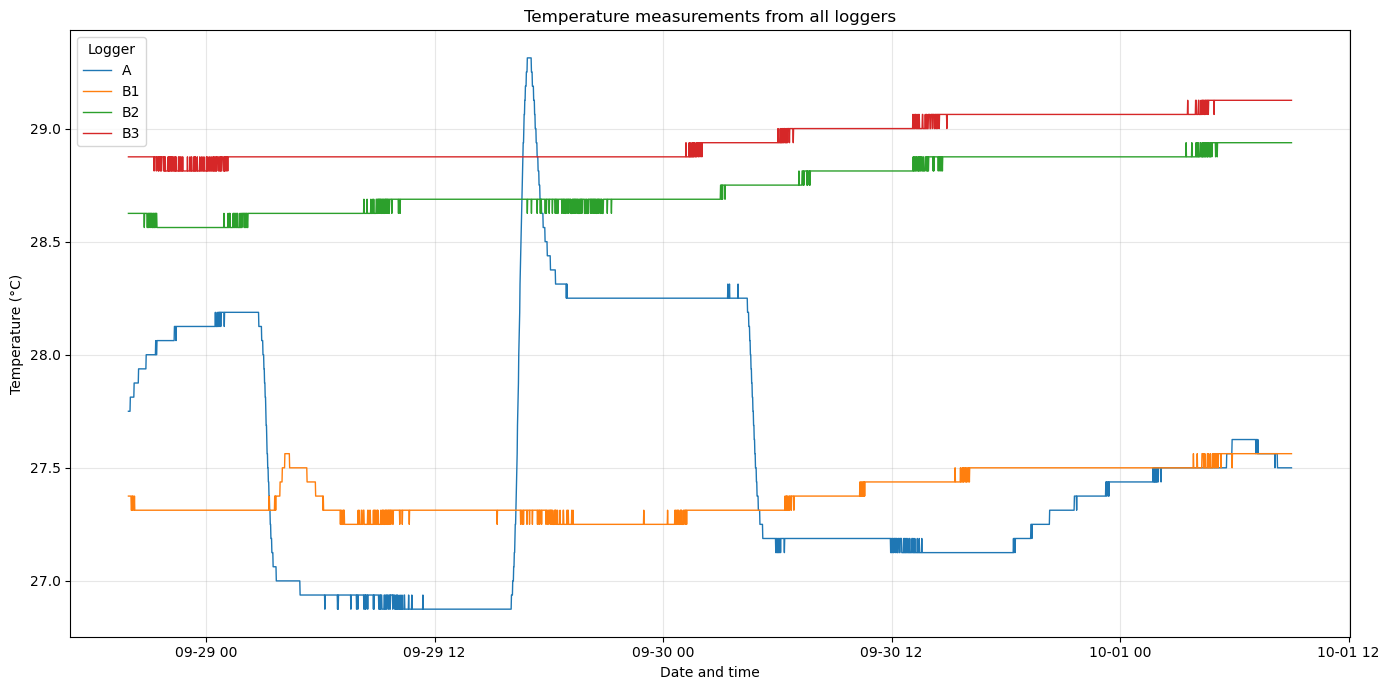

In [12]:
plt.figure(figsize=(14, 7))

for name, data in {'A': A, 'B1': B1, 'B2': B2, 'B3': B3}.items():
    datetime = pd.to_datetime(data['Date'] + ' ' + data['Time'])
    temperature = pd.to_numeric(data['Value'], errors='coerce')
    plt.plot(datetime, temperature, linewidth=1, label=name)

plt.title('Temperature measurements from all loggers')
plt.xlabel('Date and time')
plt.ylabel('Temperature (°C)')
plt.grid(alpha=0.3)
plt.legend(title='Logger')
plt.tight_layout()

C:\Users\zoelu\AppData\Local\Temp\ipykernel_18228\1391019239.py:19: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


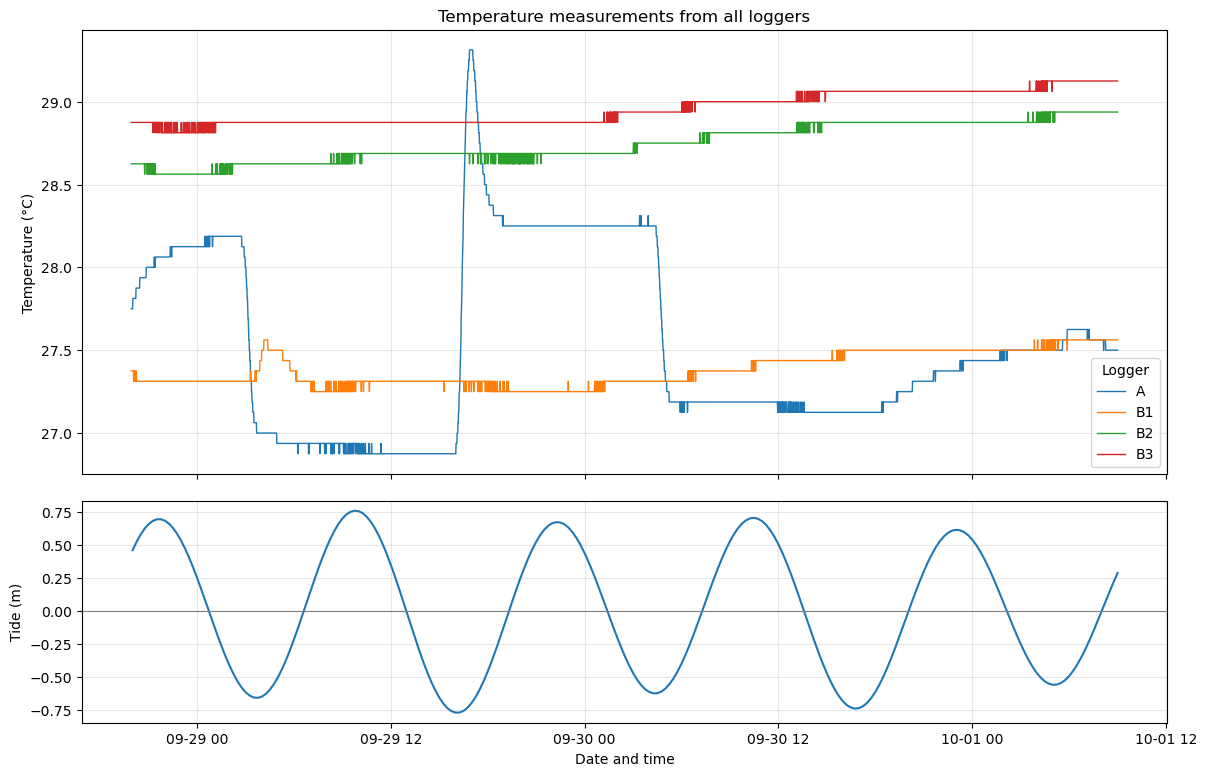

In [13]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={'height_ratios': [3, 1.5], 'hspace': 0.08})

for name, data in {'A': A, 'B1': B1, 'B2': B2, 'B3': B3}.items():
    datetime = pd.to_datetime(data['Date'] + ' ' + data['Time'])
    temperature = pd.to_numeric(data['Value'], errors='coerce')
    ax1.plot(datetime, temperature, linewidth=1, label=name)

ax1.set_title('Temperature measurements from all loggers')
ax1.set_ylabel('Temperature (°C)')
ax1.grid(alpha=0.3)
ax1.legend(title='Logger')

ax2.plot(tides_window['dates'], tides_window['tide'], linewidth=1.5)
ax2.axhline(0, color='gray', linewidth=0.8)
ax2.set_ylabel('Tide (m)')
ax2.set_xlabel('Date and time')
ax2.grid(alpha=0.3)

plt.tight_layout()